# Pac-Man AI Project - Intermediate Report

### Current Progress:

**Christian Gore & Phillip Kononenko**

For our project, we created a Pac-Man style game on a 5x5 grid with randomly generated walls. Pac-Man's goal is to visit all four corners without being caught by the ghost. The ghost has limited vision, while Pac-Man always knows where the ghost is.

So far, we have implemented the main game mechanics along with three different strategies: random, pathfinding, and Q-learning. We wanted to see how well a Q-learning player could perform compared to simpler approaches. Our original goal was to get the Q-learning player's win rate between 50% and 90%.

We built the game in Python, using NumPy to help manage the Q-learning data, Matplotlib to visualize training results, and pytest to check that our code works correctly. These libraries made it easier to test and compare the different players.

### Testing and Results

We tested our game using automated tests and by running 1,000 games for each player. All 476 automated tests passed, and we got the following results:

| **Player**   | **Win Rate** |
| ----------- | ------------ |
| Random      | 0.0%         |
| Pathfinding | 14.9%        |
| Q-learning  | 73.6%        |

Based on these results, our Q-learning player performed significantly better than the other two players. It also reached our original goal of having a win rate between 50% and 90%.

We used automated tests to check that the game mechanics and players were working correctly. We also tested the players using the same set of random seeds so that the comparisons would be fair.

### What We Have Left

At this point, most of the main functionality is finished. We still want to work toward a power-up system that allows an alternate win condition of eating the ghost but we haven't started working toward that yet. We expect that to significantly alter the outcomes, as it offers a much easier win condition but is only possible once, adding a new dynamic for the Q-learning player to process and adapt its strategy. We still want to look more closely at how the Q-learning player makes decisions and see if there are areas where it could improve. We also need to prepare our final presentation and explain our approach and results.

Overall, the game is running correctly, and we have been able to show that our Q-learning player performs better than the random and pathfinding players.


## Notebook instructions and references

This notebook contains the supplied write-up, all application source, the saved
trained policy, recorded experimental data and runnable demonstrations. Automated
test source is excluded. Only this `.ipynb` file is needed for the submission.

Use a **Python 3.11 or later Jupyter kernel**, then choose **Restart Kernel and Run All**.
NumPy and Matplotlib must be available in that kernel. If they are missing, run
`%pip install numpy matplotlib` in a new cell, restart the kernel and run all cells.

Source cells reconstruct normal Python files in a fresh temporary workspace. They
do not overwrite files beside this notebook or require Git or the original repository.
Run All displays recorded results, runs 100 random-versus-random games and replays
one recorded learned-player win. It does not retrain the policy or repeat the final
held-out evaluation. The optional training cell is disabled by default. The proposed
power-up system in the write-up is future work and is not implemented in this snapshot.

| Tool | Role | Reference |
|---|---|---|
| Python standard library | Game, seeded randomness, configuration and CLI. | https://docs.python.org/3/ |
| NumPy | Q-table storage and updates. | https://numpy.org/doc/stable/ |
| Matplotlib | Learning-curve plots. | https://matplotlib.org/stable/users/index.html |
| pytest | Original automated test suite, excluded here. | https://docs.pytest.org/en/stable/ |
| Jupyter and IPython | Notebook execution and readable file-writing cells. | https://docs.jupyter.org/ and https://ipython.readthedocs.io/ |

Dependencies are declared in the included `pyproject.toml`. Only NumPy and Matplotlib
are required for the application demonstrations. Game rules, BFS, the ghost and the
Q-learning update are implemented in the source below, without a neural-network framework.


## Setup
Run the following cells in order. The workspace location is printed so generated files can be inspected or saved.


In [1]:

import base64
import hashlib
import importlib.util
import json
import os
from pathlib import Path
import shutil
import subprocess
import sys
import tempfile
import zlib
from collections import Counter
from IPython.display import Image, Markdown, display

if sys.version_info < (3, 11):
    raise RuntimeError("Select a Python 3.11 or later kernel.")
missing = [name for name in ("numpy", "matplotlib") if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError("Missing packages: " + ", ".join(missing) + ". Run %pip install numpy matplotlib, then restart.")

import numpy
import matplotlib
SOURCE_COMMIT = '49db1ae47dfffa7101ec00811b10fa4c345678c4'
WORKSPACE = Path(tempfile.mkdtemp(prefix="pacman-course-"))
RUN_OUTPUTS = WORKSPACE / "notebook_runs"
RUN_OUTPUTS.mkdir()
for parent in ['.', 'evidence/random-vs-random', 'experiments', 'pacman', 'pacman/agents', 'reports/results']:
    (WORKSPACE / parent).mkdir(parents=True, exist_ok=True)
os.chdir(WORKSPACE)
RUN_ENV = dict(os.environ, PYTHONPATH=str(WORKSPACE), PYTHONNOUSERSITE="1", MPLBACKEND="Agg")
RUN_ENV["MPLCONFIGDIR"] = str(WORKSPACE / "matplotlib-cache")
print("Python", sys.version.split()[0], "NumPy", numpy.__version__, "Matplotlib", matplotlib.__version__)
print("Source snapshot:", SOURCE_COMMIT)
print("WORKSPACE =", WORKSPACE)


Python 3.11.14 NumPy 2.4.6 Matplotlib 3.11.2
Source snapshot: 49db1ae47dfffa7101ec00811b10fa4c345678c4
WORKSPACE = /var/folders/b7/zrvh84fd5lzdv299wwxvx5w00000gn/T/pacman-course-pe4scg9p


## Complete application source

Each cell below writes the named file and otherwise contains the original application
source. These cells do not execute the module bodies. The modules are loaded normally
by the demonstration subprocesses after reconstruction. The production application
modules are unchanged from the recorded source snapshot.


### `pacman/__init__.py`


In [2]:
%%writefile pacman/__init__.py
"""Shared foundation for the Pac-Man AI game.

Gameplay and command-line entry points are implemented by subsequent tickets.
"""


Writing pacman/__init__.py


### `pacman/__main__.py`


In [3]:
%%writefile pacman/__main__.py
"""`python -m pacman <command>`."""

import sys

from pacman.cli import main

if __name__ == "__main__":
    sys.exit(main())


Writing pacman/__main__.py


### `pacman/agents/__init__.py`


In [4]:
%%writefile pacman/agents/__init__.py
"""Agent names and the factory the CLI builds them with."""

from pacman.config import Config

AGENT_NAMES = ("random", "pathfinding", "learned")


def make_agent(name: str, config: Config, policy=None):
    """Build a named agent; the learned agent needs a policy and always plays greedily here."""
    if name == "random":
        from pacman.agents.random_agent import RandomAgent

        return RandomAgent()
    if name == "pathfinding":
        from pacman.agents.pathfinding import PathfindingAgent

        return PathfindingAgent()
    if name == "learned":
        if policy is None:
            raise ValueError("the learned agent needs a policy file (--policy)")
        from pacman.agents.learned import LearnedAgent

        return LearnedAgent(config.learner, q=policy.q, training=False)
    raise ValueError(f"unknown agent {name!r}; choose one of {', '.join(AGENT_NAMES)}")


Writing pacman/agents/__init__.py


### `pacman/agents/base.py`


In [5]:
%%writefile pacman/agents/base.py
"""Common agent contract, independent of the environment implementation."""

import random
from typing import Protocol, runtime_checkable

from pacman.env import Observation, Outcome
from pacman.grid import Direction


@runtime_checkable
class Agent(Protocol):
    name: str

    def reset(self, rng: random.Random) -> None:
        """Start a game with fresh transition caches; retain learned policy data."""
        ...

    def act(self, observation: Observation) -> Direction:
        """Choose an action. The runner never calls this after a final outcome."""
        ...

    def observe(
        self, reward: float, observation: Observation, outcome: Outcome | None,
    ) -> None:
        """Receive each transition, including the explicit final referee ruling.

        WIN/LOSS/TIE end action requests. A learned agent's configured tie_update
        independently determines whether the final TIE update bootstraps.
        """
        ...


Writing pacman/agents/base.py


### `pacman/agents/features.py`


In [6]:
%%writefile pacman/agents/features.py
"""The state features and the table index, from an observation alone."""

from dataclasses import dataclass

from pacman.agents.pathfinding import plan, remembered_open
from pacman.env import KnownCell, Observation
from pacman.grid import COLS, DELTAS, Direction, in_grid, line_of_sight

STATES = 4 * 16 * 80 * 4 * 2 * 3  # 122,880 rows; policy_io.TABLE_SHAPE must agree


@dataclass(frozen=True, slots=True)
class Features:
    step: int        # first step to the nearest unvisited corner, 0..3
    open_mask: int   # bit i set when the neighbour in direction i is known open, 0..15
    offset: int      # ghost's (row, col) offset from Pac-Man, centre removed, 0..79
    distance: int    # shortest-path distance to the ghost, bucketed 1, 2, 3, 4+, as 0..3
    seen: int        # line of sight on the remembered map, 0..1
    remaining: int   # unvisited corners minus one, 0..2

    @property
    def index(self) -> int:
        return (
            (((self.step * 16 + self.open_mask) * 80 + self.offset) * 4 + self.distance) * 2
            + self.seen
        ) * 3 + self.remaining


def features(observation: Observation) -> Features:
    """Encode an observation the game is still running from; captures are never states."""
    (pacman_row, pacman_col), (ghost_row, ghost_col) = observation.pacman, observation.ghost
    if observation.pacman == observation.ghost:
        raise ValueError("a captured Pac-Man is never a state")
    current = plan(observation)  # raises when no corner remains
    known = observation.known
    open_mask = 0
    for direction in Direction:
        d_row, d_col = DELTAS[direction]
        cell = (pacman_row + d_row, pacman_col + d_col)
        if in_grid(cell) and known[cell[0] * COLS + cell[1]] == KnownCell.OPEN:
            open_mask |= 1 << direction
    k = (ghost_row - pacman_row + 4) * 9 + (ghost_col - pacman_col + 4)
    offset = k - 1 if k > 40 else k
    distance = min(current.distances[observation.ghost], 4) - 1
    seen = int(line_of_sight(observation.ghost, observation.pacman, remembered_open(observation)))
    return Features(int(current.step), open_mask, offset, distance, seen, current.remaining - 1)


def state_index(observation: Observation) -> int:
    return features(observation).index


Writing pacman/agents/features.py


### `pacman/agents/learned.py`


In [7]:
%%writefile pacman/agents/learned.py
"""Tabular Q-learning over the encoded state features."""

import random

import numpy

from pacman.agents.features import state_index
from pacman.config import LearnerSettings
from pacman.env import Observation, Outcome
from pacman.grid import Direction
from pacman.policy_io import TABLE_SHAPE
from pacman.rng import pick


class LearnedAgent:
    """Greedy outside training; epsilon-greedy with Q updates in training."""

    name = "learned"

    def __init__(
        self, settings: LearnerSettings, q: numpy.ndarray | None = None, training: bool = False,
    ) -> None:
        if q is None:
            q = numpy.zeros(TABLE_SHAPE, dtype=numpy.float64)
        elif not isinstance(q, numpy.ndarray) or q.dtype != numpy.float64 or q.shape != TABLE_SHAPE:
            raise ValueError(f"q must be a float64 array of shape {TABLE_SHAPE}")
        self.settings = settings
        self.q = q
        self.training = training
        self.epsilon = 0.0  # the training loop sets it before each episode
        self.rng: random.Random | None = None
        self._state: int | None = None      # state of the pending transition, set by act
        self._action: Direction | None = None
        self._next_state: int | None = None  # cache for the next act; only a training observe fills it

    def reset(self, rng: random.Random) -> None:
        """New game: fresh generator and empty transition cache; the table is kept."""
        self.rng = rng
        self._state = None
        self._action = None
        self._next_state = None

    def act(self, observation: Observation) -> Direction:
        state = self._next_state if self._next_state is not None else state_index(observation)
        self._next_state = None
        if self.training and self.rng.random() < self.epsilon:
            action = Direction(pick(self.rng, 4))
        else:
            action = Direction(int(numpy.argmax(self.q[state])))  # first maximum: direction order
        self._state, self._action = state, action
        return action

    def observe(self, reward: float, observation: Observation, outcome: Outcome | None) -> None:
        if not self.training:
            return
        if self._action is None:
            raise RuntimeError("observe without a pending action; act comes first in every game")
        state, action = self._state, self._action
        settings = self.settings
        bootstrap = outcome is None or (outcome is Outcome.TIE and settings.tie_update == "bootstrap")
        if bootstrap:
            next_state = state_index(observation)
            target = reward + settings.discount * float(numpy.max(self.q[next_state]))
        else:
            target = reward  # WIN, LOSS or a terminal TIE: the final observation is never encoded
        self.q[state, action] += settings.learning_rate * (target - self.q[state, action])
        self._next_state = next_state if outcome is None else None
        self._state = None
        self._action = None


Writing pacman/agents/learned.py


### `pacman/agents/pathfinding.py`


In [8]:
%%writefile pacman/agents/pathfinding.py
"""The pathfinding baseline and the plan it shares with the features."""

from collections.abc import Mapping
from dataclasses import dataclass
import random

from pacman.env import KnownCell, Observation, Outcome
from pacman.grid import COLS, Cell, Direction, Passable, bfs, first_step

# Equally near corners are chosen in this order.
CORNER_ORDER: tuple[Cell, ...] = ((0, 4), (4, 0), (4, 4))


def remembered_open(observation: Observation) -> Passable:
    """Pac-Man's passable predicate: anything not remembered as a wall counts as open."""
    known = observation.known
    return lambda cell: known[cell[0] * COLS + cell[1]] != KnownCell.WALL


@dataclass(frozen=True, slots=True)
class Plan:
    target: Cell
    step: Direction
    distances: Mapping[Cell, int]
    remaining: int


def plan(observation: Observation) -> Plan:
    """The nearest unvisited corner on the remembered map and the first step towards it."""
    passable = remembered_open(observation)
    distances = bfs(observation.pacman, passable)
    unvisited = [corner for corner in CORNER_ORDER if corner not in observation.visited]
    if not unvisited:
        raise ValueError("every corner is visited; there is nothing left to plan")
    target = min(unvisited, key=lambda corner: distances[corner])
    return Plan(target, first_step(observation.pacman, target, passable), distances, len(unvisited))


class PathfindingAgent:
    name = "pathfinding"

    def reset(self, rng: random.Random | None) -> None:
        return None

    def act(self, observation: Observation) -> Direction:
        return plan(observation).step

    def observe(self, reward: float, observation: Observation, outcome: Outcome | None) -> None:
        return None


Writing pacman/agents/pathfinding.py


### `pacman/agents/random_agent.py`


In [9]:
%%writefile pacman/agents/random_agent.py
"""The random baseline: one uniform draw per step."""

import random

from pacman.env import Observation, Outcome
from pacman.grid import Direction
from pacman.rng import pick


class RandomAgent:
    name = "random"

    def reset(self, rng: random.Random) -> None:
        self.rng = rng

    def act(self, observation: Observation) -> Direction:
        return Direction(pick(self.rng, 4))

    def observe(self, reward: float, observation: Observation, outcome: Outcome | None) -> None:
        return None


Writing pacman/agents/random_agent.py


### `pacman/cli.py`


In [10]:
%%writefile pacman/cli.py
"""The five commands: train, evaluate, check, simulate and watch.

Only this module parses arguments or prints; the services return data and strings.
Every error ends the command with a message on standard error and a non-zero exit.
"""

import argparse
from dataclasses import fields, replace
import os
from pathlib import Path
import sys
import time

from pacman import evaluate
from pacman import train as training
from pacman.agents import AGENT_NAMES, make_agent
from pacman.config import Config
from pacman.env import Environment
from pacman.episode import play_episode
from pacman.evaluate import (
    TABLE_HEADER,
    compare,
    difficulty_check,
    format_header,
    format_report,
    format_summary_row,
    knob_differences,
    run_split,
    summarise,
    write_eval_json,
)
from pacman.mapgen import Split, split_of_seed
from pacman.policy_io import Policy, load_policy
from pacman.referee import Referee
from pacman.render import render_frame, use_plain

CLEAR_SCREEN = "\x1b[H\x1b[2J"  # cursor home, then clear


def apply_sets(config: Config, sets: list[str]) -> Config:
    """Apply `--set name=value` overrides by bare field name, with type-checked values."""
    for setting in sets:
        name, separator, raw = setting.partition("=")
        if not separator or not name:
            raise ValueError(f"--set needs NAME=VALUE, got {setting!r}")
        config = _apply_set(config, name, raw)
    return config


def _apply_set(config: Config, name: str, raw: str) -> Config:
    for section in ("game", "learner"):
        part = getattr(config, section)
        for field in fields(part):
            if field.name == name:
                value = _parse_value(field.type, raw, name)
                return replace(config, **{section: replace(part, **{name: value})})
    raise ValueError(f"unknown setting {name!r}")


def _parse_value(kind, raw: str, name: str):
    try:
        if kind is int:
            return int(raw)
        if kind is float:
            return float(raw)
    except ValueError:
        raise ValueError(f"{name} must be {'an integer' if kind is int else 'a number'}, got {raw!r}") from None
    return raw


def load_config(path: str | Path | None, sets: list[str]) -> Config:
    """The configuration of a command: defaults or a JSON file, then the `--set` overrides."""
    config = Config() if path is None else Config.from_json(Path(path).read_text())
    return apply_sets(config, sets)


def policy_config(args: argparse.Namespace, policy: Policy) -> Config:
    """A policy's configuration with overrides; a differing game knob is an error."""
    base = policy.config if args.config is None else Config.from_json(Path(args.config).read_text())
    config = apply_sets(base, args.set)
    differences = knob_differences(config.game, policy.config.game)
    if differences:
        listed = ", ".join(f"{name}={now} (policy: {stored})" for name, (now, stored) in differences.items())
        raise ValueError(f"game knobs differ from the policy's: {listed}")
    return config


def parse_args(argv=None) -> argparse.Namespace:
    parser = argparse.ArgumentParser(prog="pacman", description="Grid-world Pac-Man against a ghost.")
    commands = parser.add_subparsers(dest="command", required=True, metavar="COMMAND")

    def common(command: argparse.ArgumentParser) -> None:
        command.add_argument("--config", type=Path, metavar="FILE", help="JSON configuration file")
        command.add_argument(
            "--set", action="append", default=[], metavar="NAME=VALUE",
            help="override one game knob or learner setting by its bare name; repeatable",
        )

    train = commands.add_parser("train", help="train the learned agent and write a run directory")
    train.add_argument("--out", type=Path, required=True, metavar="DIR")
    common(train)

    evaluate_ = commands.add_parser("evaluate", help="play all agents on a split and report")
    evaluate_.add_argument("--split", choices=("val", "test"), required=True)
    evaluate_.add_argument("--policy", type=Path, required=True, metavar="FILE")
    common(evaluate_)

    check = commands.add_parser("check", help="play the baselines on validation under the given knobs")
    check.add_argument("--policy", type=Path, metavar="FILE")
    common(check)

    simulate = commands.add_parser("simulate", help="play games without graphics and summarise")
    simulate.add_argument("--agent", action="append", choices=AGENT_NAMES, required=True, metavar="NAME")
    simulate.add_argument("--split", choices=("train", "val", "test"), required=True)
    simulate.add_argument("--games", type=int, required=True, metavar="N")
    simulate.add_argument("--policy", type=Path, metavar="FILE")
    common(simulate)

    watch = commands.add_parser("watch", help="play one game and draw it")
    watch.add_argument("--agent", choices=AGENT_NAMES, required=True, metavar="NAME")
    watch.add_argument("--seed", type=int, required=True)
    watch.add_argument("--policy", type=Path, metavar="FILE")
    watch.add_argument("--delay", type=float, default=0.25, metavar="SECONDS")
    watch.add_argument("--plain", action="store_true", help="plain-text frames instead of pixel art")
    common(watch)
    return parser.parse_args(argv)


def _train(args: argparse.Namespace) -> None:
    config = load_config(args.config, args.set)
    out = training.prepare_output_dir(args.out)  # refuse an existing run before training
    import pacman.plot  # noqa: F401  a missing Matplotlib fails here, not after the run

    def progress(episodes: int, win_rate: float) -> None:
        print(
            f"episodes {episodes}: validation win rate {100 * win_rate:.1f}%"
            f" ({training.CURVE_GAMES} games)", flush=True,
        )

    result = training.train(config, on_progress=progress)
    print(TABLE_HEADER)
    print(format_summary_row(result.validation))
    training.write_outputs(out, result)
    print(f"wrote {out / 'policy.npz'}, curve.csv, curve.png and config.json")


def _evaluate(args: argparse.Namespace) -> None:
    policy = load_policy(args.policy)
    config = policy_config(args, policy)
    split = Split(args.split)
    games = evaluate.FULL_GAMES
    records = {
        name: run_split(config, make_agent(name, config, policy), split, games) for name in AGENT_NAMES
    }
    summaries = [summarise(name, agent_records) for name, agent_records in records.items()]
    comparisons = [compare(records["learned"], records[name]) for name in ("random", "pathfinding")]
    print(format_report(split, games, config.game, summaries, comparisons))
    path = Path(args.policy).parent / f"eval-{split.value}.json"
    write_eval_json(path, config, [record for agent_records in records.values() for record in agent_records])
    print(f"wrote {path}")


def _check(args: argparse.Namespace) -> None:
    config = load_config(args.config, args.set)
    policy = load_policy(args.policy) if args.policy is not None else None
    result = difficulty_check(config, policy)
    print(format_header(Split.VAL, evaluate.FULL_GAMES, config.game))
    print(TABLE_HEADER)
    for summary in result.baselines:
        print(format_summary_row(summary))
    if result.stored is not None:
        print(format_summary_row(result.stored))
        knobs = []
        for field in fields(config.game):
            text = f"{field.name}={getattr(config.game, field.name)}"
            if field.name in result.knobs:
                text += f"* (policy: {result.knobs[field.name][1]})"
            knobs.append(text)
        print("policy knobs: " + " ".join(knobs) + ("  (* differs from the policy)" if result.knobs else ""))


def _simulate(args: argparse.Namespace) -> None:
    policy = load_policy(args.policy) if args.policy is not None else None
    config = policy_config(args, policy) if policy is not None else load_config(args.config, args.set)
    split = Split(args.split)
    agents = [make_agent(name, config, policy) for name in args.agent]
    summaries = evaluate.simulate(config, agents, split, args.games)
    print(format_report(split, args.games, config.game, summaries))


def _watch(args: argparse.Namespace) -> None:
    policy = load_policy(args.policy) if args.policy is not None else None
    config = policy_config(args, policy) if policy is not None else load_config(args.config, args.set)
    split_of_seed(args.seed)  # the split comes from the seed; an unknown seed is an error
    agent = make_agent(args.agent, config, policy)
    plain = use_plain(args.plain, sys.stdout.isatty(), os.environ)
    shown = False

    def show(frame) -> None:
        nonlocal shown
        if shown:
            time.sleep(args.delay)
            if plain:
                print()  # plain frames scroll, which suits logs and tests
        if not plain:
            print(CLEAR_SCREEN, end="")  # pixel art redraws in place, so the game animates
        print(render_frame(frame, plain), flush=True)
        shown = True

    play_episode(Environment(config), Referee(config.game.max_steps), agent, args.seed, on_frame=show)


COMMANDS = {
    "train": _train, "evaluate": _evaluate, "check": _check, "simulate": _simulate, "watch": _watch,
}


def main(argv=None) -> int:
    args = parse_args(argv)
    try:
        COMMANDS[args.command](args)
    except KeyboardInterrupt:  # Ctrl-C in watch or train: no traceback, the usual exit code
        print(file=sys.stderr)
        return 130
    except Exception as error:  # the command boundary: every failure is a message and exit 1
        if os.environ.get("PACMAN_DEBUG"):
            raise
        print(f"error: {error}", file=sys.stderr)
        return 1
    return 0


Writing pacman/cli.py


### `pacman/config.py`


In [11]:
%%writefile pacman/config.py
"""Immutable game and learner settings, with validated JSON serialisation."""

from dataclasses import asdict, dataclass, field, fields
import json
import math
from typing import Any


def _integer(name: str, value: Any, minimum: int, maximum: int | None = None) -> None:
    if type(value) is not int:
        raise ValueError(f"{name} must be an integer")
    if value < minimum or (maximum is not None and value > maximum):
        upper = f" and at most {maximum}" if maximum is not None else ""
        raise ValueError(f"{name} must be at least {minimum}{upper}")


def _number(
    name: str,
    value: Any,
    minimum: float | None = None,
    maximum: float | None = None,
    *,
    minimum_exclusive: bool = False,
) -> None:
    if isinstance(value, bool) or not isinstance(value, (int, float)):
        raise ValueError(f"{name} must be a finite number")
    try:
        finite = math.isfinite(value)
    except OverflowError:
        finite = False
    if not finite:
        raise ValueError(f"{name} must be a finite number")
    if minimum is not None:
        if value < minimum or (minimum_exclusive and value == minimum):
            relation = "greater than" if minimum_exclusive else "at least"
            raise ValueError(f"{name} must be {relation} {minimum}")
    if maximum is not None and value > maximum:
        raise ValueError(f"{name} must be at most {maximum}")


@dataclass(frozen=True, slots=True)
class GameKnobs:
    ghost_move_prob: float = 1.0
    wall_density: float = 0.20
    max_walls: int = 6
    min_loops: int = 4
    max_steps: int = 100

    def __post_init__(self) -> None:
        _number("ghost_move_prob", self.ghost_move_prob, 0, 1)
        _number("wall_density", self.wall_density, 0, 1)
        _integer("max_walls", self.max_walls, 0)
        _integer("min_loops", self.min_loops, 0)
        _integer("max_steps", self.max_steps, 1)


@dataclass(frozen=True, slots=True)
class LearnerSettings:
    reward_win: float = 100.0
    reward_loss: float = -100.0
    reward_corner: float = 1.0
    reward_step: float = -0.05
    learning_rate: float = 0.1
    discount: float = 0.99
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_fraction: float = 0.5
    episodes: int = 50_000
    tie_update: str = "bootstrap"

    def __post_init__(self) -> None:
        for name in ("reward_win", "reward_loss", "reward_corner", "reward_step"):
            _number(name, getattr(self, name))
        _number("learning_rate", self.learning_rate, 0, 1, minimum_exclusive=True)
        _number("discount", self.discount, 0, 1)
        _number("epsilon_start", self.epsilon_start, 0, 1)
        _number("epsilon_end", self.epsilon_end, 0, self.epsilon_start)
        _number(
            "epsilon_decay_fraction", self.epsilon_decay_fraction,
            0, 1, minimum_exclusive=True,
        )
        _integer("episodes", self.episodes, 1, 1_000_000)
        if not isinstance(self.tie_update, str) or self.tie_update not in (
            "bootstrap", "terminal",
        ):
            raise ValueError("tie_update must be 'bootstrap' or 'terminal'")


def _reject_json_constant(value: str) -> None:
    raise ValueError(f"Non-finite JSON value is not allowed: {value}")


def _unique_json_object(pairs: list[tuple[str, Any]]) -> dict[str, Any]:
    result: dict[str, Any] = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f"Duplicate JSON key: {key}")
        result[key] = value
    return result


def _section(data: Any, model: type, name: str) -> dict[str, Any]:
    if not isinstance(data, dict):
        raise ValueError(f"{name} must be a JSON object")
    unknown = data.keys() - {item.name for item in fields(model)}
    if unknown:
        raise ValueError(f"Unknown {name} settings: {', '.join(sorted(unknown))}")
    return data


@dataclass(frozen=True, slots=True)
class Config:
    game: GameKnobs = field(default_factory=GameKnobs)
    learner: LearnerSettings = field(default_factory=LearnerSettings)

    def __post_init__(self) -> None:
        if not isinstance(self.game, GameKnobs):
            raise ValueError("game must be GameKnobs")
        if not isinstance(self.learner, LearnerSettings):
            raise ValueError("learner must be LearnerSettings")

    def to_json(self) -> str:
        """Return a stable JSON representation of every setting."""
        return json.dumps(asdict(self), indent=2, sort_keys=True, allow_nan=False) + "\n"

    @classmethod
    def from_json(cls, text: str) -> "Config":
        """Read settings; unknown or duplicate keys fail, omitted keys default."""
        data = json.loads(
            text,
            parse_constant=_reject_json_constant,
            object_pairs_hook=_unique_json_object,
        )
        data = _section(data, cls, "configuration")
        game = _section(data.get("game", {}), GameKnobs, "game")
        learner = _section(data.get("learner", {}), LearnerSettings, "learner")
        return cls(game=GameKnobs(**game), learner=LearnerSettings(**learner))


Writing pacman/config.py


### `pacman/env.py`


In [12]:
%%writefile pacman/env.py
"""The environment: one episode's true map, ghost, Pac-Man memory and rewards."""

from dataclasses import dataclass
from enum import Enum, IntEnum

from pacman.config import Config
from pacman.ghost import Ghost
from pacman.grid import COLS, CORNERS, ROWS, Cell, Direction, move, neighbours
from pacman.mapgen import GameMap, generate, split_of_seed
from pacman.rng import derive

PACMAN_START: Cell = (0, 0)


class Outcome(Enum):
    WIN = "win"
    LOSS = "loss"
    TIE = "tie"


class KnownCell(IntEnum):
    UNKNOWN = 0
    OPEN = 1
    WALL = 2


@dataclass(frozen=True, slots=True)
class Observation:
    pacman: Cell
    ghost: Cell
    visited: frozenset[Cell]
    known: tuple[KnownCell, ...]

    def __post_init__(self) -> None:
        object.__setattr__(self, "visited", frozenset(self.visited))
        object.__setattr__(self, "known", tuple(self.known))
        if len(self.known) != ROWS * COLS:
            raise ValueError("known must contain 25 row-major cells")


@dataclass(frozen=True, slots=True)
class StepResult:
    observation: Observation
    reward: float
    outcome: Outcome | None


class Environment:
    """Holds one episode at a time; the only owner of the true map and the ghost."""

    def __init__(self, config: Config) -> None:
        self.config = config
        self.game_map: GameMap | None = None
        self.outcome: Outcome | None = None
        # Episode state; `reset` gives every field its real value.
        self.pacman: Cell = PACMAN_START
        self.ghost: Ghost | None = None
        self.visited: set[Cell] = set()
        self.known: list[KnownCell] = []

    def reset(self, seed: int, game_map: GameMap | None = None) -> Observation:
        """Start an episode on the seed's map, or on a hand-built map for tests."""
        if game_map is None:
            game_map = generate(seed, split_of_seed(seed), self.config)
        self.game_map = game_map
        self.pacman = PACMAN_START
        self.ghost = Ghost(derive(seed, "ghost"), self.config.game.ghost_move_prob)
        self.visited = {PACMAN_START}
        self.known = [KnownCell.UNKNOWN] * (ROWS * COLS)
        self.outcome = None
        self._sense(game_map)
        return self._observation()

    def step(self, action: Direction, t: int) -> StepResult:
        """Advance one turn; `t` only stamps the ghost's visit record."""
        game_map, ghost = self.game_map, self.ghost
        if game_map is None or ghost is None:
            raise RuntimeError("reset the environment before stepping")
        if self.outcome is not None:
            raise RuntimeError(f"the episode ended in a {self.outcome.value}")
        rewards = self.config.learner
        reward = rewards.reward_step
        self.pacman = move(self.pacman, action, game_map.is_open)
        if self.pacman == ghost.cell:
            reward += rewards.reward_loss
            return self._end(Outcome.LOSS, reward)
        if self.pacman in CORNERS and self.pacman not in self.visited:
            self.visited.add(self.pacman)
            reward += rewards.reward_corner
            if len(self.visited) == len(CORNERS):
                reward += rewards.reward_win
                return self._end(Outcome.WIN, reward)
        self._sense(game_map)
        ghost.act(self.pacman, game_map, t)
        if ghost.cell == self.pacman:
            reward += rewards.reward_loss
            return self._end(Outcome.LOSS, reward)
        return StepResult(self._observation(), reward, None)

    def _sense(self, game_map: GameMap) -> None:
        """Record each in-grid neighbour of Pac-Man as open or a wall."""
        for row, col in neighbours(self.pacman):
            self.known[row * COLS + col] = (
                KnownCell.OPEN if game_map.is_open((row, col)) else KnownCell.WALL
            )

    def _observation(self) -> Observation:
        assert self.ghost is not None
        return Observation(self.pacman, self.ghost.cell, self.visited, self.known)

    def _end(self, outcome: Outcome, reward: float) -> StepResult:
        self.outcome = outcome
        return StepResult(self._observation(), reward, outcome)


Writing pacman/env.py


### `pacman/episode.py`


In [13]:
%%writefile pacman/episode.py
"""The one episode loop that joins an environment, the referee and an agent."""

from collections.abc import Callable
from dataclasses import dataclass
from typing import TYPE_CHECKING

from pacman.env import Environment, Observation, Outcome
from pacman.grid import line_of_sight
from pacman.referee import Referee
from pacman.rng import derive

if TYPE_CHECKING:  # the loop never imports a concrete agent at runtime
    from pacman.agents.base import Agent


@dataclass(frozen=True, slots=True)
class EpisodeRecord:
    seed: int
    agent: str
    outcome: Outcome
    steps: int
    episode_return: float


@dataclass(frozen=True, slots=True)
class Frame:
    """What watch mode draws after reset and after each step."""

    observation: Observation
    t: int
    outcome: Outcome | None
    ghost_sees: bool
    max_steps: int


def play_episode(
    environment: Environment,
    referee: Referee,
    agent: "Agent",
    seed: int,
    on_frame: Callable[[Frame], None] | None = None,
) -> EpisodeRecord:
    """Play one game to the referee's ruling; nothing here branches on the agent."""
    observation = environment.reset(seed)
    referee.start()
    agent.reset(derive(seed, "agent"))
    episode_return = 0.0
    if on_frame is not None:
        on_frame(_frame(environment, observation, 0, None, referee.max_steps))
    while True:
        t = referee.next_move()
        result = environment.step(agent.act(observation), t)
        outcome = referee.rule(result)
        agent.observe(result.reward, result.observation, outcome)
        episode_return += result.reward
        if on_frame is not None:
            on_frame(_frame(environment, result.observation, t, outcome, referee.max_steps))
        if outcome is not None:
            return EpisodeRecord(seed, agent.name, outcome, t, episode_return)
        observation = result.observation


def _frame(
    environment: Environment,
    observation: Observation,
    t: int,
    outcome: Outcome | None,
    max_steps: int,
) -> Frame:
    assert environment.game_map is not None
    sees = line_of_sight(observation.ghost, observation.pacman, environment.game_map.is_open)
    return Frame(observation, t, outcome, sees, max_steps)


Writing pacman/episode.py


### `pacman/evaluate.py`


In [14]:
%%writefile pacman/evaluate.py
"""Paired evaluation on a split, summaries, the report layout, replay JSON and the
difficulty check. Everything returns data or strings; the CLI prints.
"""

from collections.abc import Iterable, Sequence
from dataclasses import dataclass, fields
import json
from pathlib import Path
from typing import Any

from pacman.agents.pathfinding import PathfindingAgent
from pacman.agents.random_agent import RandomAgent
from pacman.config import Config, GameKnobs
from pacman.env import Environment, Outcome
from pacman.episode import EpisodeRecord, play_episode
from pacman.mapgen import SPLIT_SEEDS, Split
from pacman.policy_io import Policy, ValidationSummary
from pacman.referee import Referee
from pacman.stats import discordant_pairs, mcnemar_one_sided, mean_steps, wilson

FULL_GAMES = 1_000  # An evaluation plays every seed of its split.

TABLE_HEADER = "agent         wins                  losses                ties                  steps/win"


@dataclass(frozen=True, slots=True)
class Summary:
    agent: str
    games: int
    wins: int
    losses: int
    ties: int
    win_interval: tuple[float, float]
    loss_interval: tuple[float, float]
    tie_interval: tuple[float, float]
    mean_steps_to_win: float | None


@dataclass(frozen=True, slots=True)
class Comparison:
    learned: str
    baseline: str
    b: int
    c: int
    p: float


@dataclass(frozen=True, slots=True)
class DifficultyCheck:
    baselines: tuple[Summary, ...]
    stored: Summary | None
    knobs: dict[str, tuple[Any, Any]]


def run_split(config: Config, agent, split: Split, games: int) -> list[EpisodeRecord]:
    """Play the first `games` seeds of the split, in seed order, with the agent as given."""
    seeds = SPLIT_SEEDS[split]
    if type(games) is not int or games < 1 or games > len(seeds):
        raise ValueError(f"games must be between 1 and {len(seeds)} for the {split.value} split")
    if getattr(agent, "training", False):
        # Evaluation is greedy. A training agent here would learn from held-out seeds.
        raise ValueError(
            f"{agent.name} is in training mode; evaluation plays greedily, so set"
            " training = False or use a separate evaluation agent"
        )
    environment = Environment(config)
    referee = Referee(config.game.max_steps)
    return [play_episode(environment, referee, agent, seed) for seed in seeds[:games]]


def summarise(agent: str, records: Iterable[EpisodeRecord]) -> Summary:
    """Counts, 95% Wilson intervals and mean steps to a win for one agent's records."""
    records = tuple(records)
    outcomes = [record.outcome for record in records]
    games = len(outcomes)
    if games == 0:
        raise ValueError("nothing to summarise")
    wins = outcomes.count(Outcome.WIN)
    losses = outcomes.count(Outcome.LOSS)
    ties = outcomes.count(Outcome.TIE)
    steps = mean_steps(record.steps for record in records if record.outcome is Outcome.WIN)
    return Summary(
        agent, games, wins, losses, ties,
        wilson(wins, games), wilson(losses, games), wilson(ties, games), steps,
    )


def summary_of_validation(validation: ValidationSummary, agent: str = "learned") -> Summary:
    """The summary a policy file stores for its final validation run."""
    games = validation.games
    return Summary(
        agent, games, validation.wins, validation.losses, validation.ties,
        wilson(validation.wins, games), wilson(validation.losses, games),
        wilson(validation.ties, games), validation.mean_steps_to_win,
    )


def _one_agent(records: Sequence[EpisodeRecord]) -> str:
    names = {record.agent for record in records}
    if len(names) != 1:
        raise ValueError("records of exactly one agent are expected")
    return names.pop()


def _wins_by_seed(records: Sequence[EpisodeRecord]) -> dict[int, bool]:
    wins = {record.seed: record.outcome is Outcome.WIN for record in records}
    if len(wins) != len(records):
        raise ValueError("a seed appears more than once")
    return wins


def compare(learned: Sequence[EpisodeRecord], baseline: Sequence[EpisodeRecord]) -> Comparison:
    """The one-sided exact McNemar test of the learned agent against a baseline."""
    b, c = discordant_pairs(_wins_by_seed(learned), _wins_by_seed(baseline))
    return Comparison(_one_agent(learned), _one_agent(baseline), b, c, mcnemar_one_sided(b, c))


def format_header(split: Split, games: int, game: GameKnobs) -> str:
    knobs = " ".join(f"{field.name}={getattr(game, field.name)}" for field in fields(game))
    return f"split {split.value}, {games} games per agent, knobs: {knobs}"


def _cell(count: int, games: int, interval: tuple[float, float], width: int) -> str:
    low, high = interval
    return f"{count:>{width}} {100 * count / games:5.1f}% [{100 * low:4.1f},{100 * high:5.1f}]"


def format_summary_row(summary: Summary) -> str:
    """One summary-table row with fixed column widths."""
    steps = "n/a" if summary.mean_steps_to_win is None else f"{summary.mean_steps_to_win:.1f}"
    return (
        f"{summary.agent:<12}"
        + _cell(summary.wins, summary.games, summary.win_interval, 5)
        + _cell(summary.losses, summary.games, summary.loss_interval, 6)
        + _cell(summary.ties, summary.games, summary.tie_interval, 5)
        + f"   {steps}"
    )


def format_comparison(comparison: Comparison) -> str:
    label = f"{comparison.learned} vs {comparison.baseline}:"
    return f"{label:<25}b={comparison.b} c={comparison.c} one-sided exact McNemar p={comparison.p:.4f}"


def format_report(
    split: Split, games: int, game: GameKnobs,
    summaries: Iterable[Summary], comparisons: Iterable[Comparison] = (),
) -> str:
    lines = [format_header(split, games, game), TABLE_HEADER]
    lines += [format_summary_row(summary) for summary in summaries]
    lines += [format_comparison(comparison) for comparison in comparisons]
    return "\n".join(lines)


def write_eval_json(path: str | Path, config: Config, records: Iterable[EpisodeRecord]) -> None:
    """The configuration and every record, so any evaluated game can be replayed."""
    data = {
        "config": json.loads(config.to_json()),
        "records": [
            {
                "seed": record.seed, "agent": record.agent, "outcome": record.outcome.value,
                "steps": record.steps, "episode_return": record.episode_return,
            }
            for record in records
        ],
    }
    Path(path).write_text(json.dumps(data, indent=2, sort_keys=True, allow_nan=False) + "\n")


def read_eval_json(path: str | Path) -> tuple[Config, list[EpisodeRecord]]:
    data = json.loads(Path(path).read_text())
    config = Config.from_json(json.dumps(data["config"]))
    records = [
        EpisodeRecord(
            item["seed"], item["agent"], Outcome(item["outcome"]), item["steps"],
            item["episode_return"],
        )
        for item in data["records"]
    ]
    return config, records


def knob_differences(current: GameKnobs, stored: GameKnobs) -> dict[str, tuple[Any, Any]]:
    """Game knobs whose current value differs from the one a policy was trained with."""
    return {
        field.name: (getattr(current, field.name), getattr(stored, field.name))
        for field in fields(current)
        if getattr(current, field.name) != getattr(stored, field.name)
    }


def difficulty_check(config: Config, policy: Policy | None = None) -> DifficultyCheck:
    """The baselines on the validation split under the given knobs; never trains."""
    baselines = tuple(
        summarise(agent.name, run_split(config, agent, Split.VAL, FULL_GAMES))
        for agent in (RandomAgent(), PathfindingAgent())
    )
    if policy is None:
        return DifficultyCheck(baselines, None, {})
    return DifficultyCheck(
        baselines, summary_of_validation(policy.validation),
        knob_differences(config.game, policy.config.game),
    )


def simulate(config: Config, agents: Iterable, split: Split, games: int) -> list[Summary]:
    """The per-agent summary of the first `games` seeds of a split, no graphics."""
    return [summarise(agent.name, run_split(config, agent, split, games)) for agent in agents]


Writing pacman/evaluate.py


### `pacman/ghost.py`


In [15]:
%%writefile pacman/ghost.py
"""The ghost: row/column vision, BFS chase, pursuit of the last sighting, search."""

import random

from pacman.grid import Cell, Passable, first_step, line_of_sight, move, neighbours
from pacman.mapgen import GameMap
from pacman.rng import pick

GHOST_START: Cell = (4, 4)


class Ghost:
    """One ghost for one episode; the environment calls `act` once per step."""

    def __init__(
        self, rng: random.Random, move_prob: float = 1.0, start: Cell = GHOST_START,
    ) -> None:
        self.cell = start
        self.last_seen: Cell | None = None
        self.last_visit: dict[Cell, int] = {start: 0}
        self.rng = rng
        self.move_prob = move_prob

    def act(self, pacman: Cell, game_map: GameMap, t: int) -> None:
        """One ghost move: vision, the move draw, then chase, pursue or search."""
        passable = game_map.is_open
        if line_of_sight(self.cell, pacman, passable):
            self.last_seen = pacman
        if not self.rng.random() < self.move_prob:
            return
        if self.last_seen is not None:
            self.cell = move(self.cell, first_step(self.cell, self.last_seen, passable), passable)
        else:
            self.cell = self._least_recent(passable)
        if self.cell == self.last_seen:
            self.last_seen = None
        self.last_visit[self.cell] = t

    def _least_recent(self, passable: Passable) -> Cell:
        """The least recently visited open neighbour; never visited counts as oldest."""
        candidates = [cell for cell in neighbours(self.cell) if passable(cell)]
        if not candidates:
            raise ValueError(f"the ghost at {self.cell} has no open neighbour to move to")
        oldest = min(self.last_visit.get(cell, -1) for cell in candidates)
        ties = [cell for cell in candidates if self.last_visit.get(cell, -1) == oldest]
        if len(ties) == 1:
            return ties[0]
        return ties[pick(self.rng, len(ties))]


Writing pacman/ghost.py


### `pacman/grid.py`


In [16]:
%%writefile pacman/grid.py
"""Fixed-grid types, movement, planning and sight."""

from collections import deque
from collections.abc import Callable
from enum import IntEnum
from typing import TypeAlias

ROWS = COLS = 5
Cell: TypeAlias = tuple[int, int]
Passable: TypeAlias = Callable[[Cell], bool]


class Direction(IntEnum):
    UP = 0
    RIGHT = 1
    DOWN = 2
    LEFT = 3


DELTAS: tuple[Cell, ...] = ((-1, 0), (0, 1), (1, 0), (0, -1))
CORNERS: tuple[Cell, ...] = ((0, 0), (0, COLS - 1), (ROWS - 1, 0), (ROWS - 1, COLS - 1))


def in_grid(cell: Cell) -> bool:
    row, col = cell
    return 0 <= row < ROWS and 0 <= col < COLS


def _neighbours(cell: Cell) -> tuple[Cell, ...]:
    row, col = cell
    candidates = ((row + d_row, col + d_col) for d_row, d_col in DELTAS)
    return tuple(candidate for candidate in candidates if in_grid(candidate))


# The grid never changes, so the neighbour lists are computed once; BFS is the
# hot path of training and calls this millions of times.
NEIGHBOURS: dict[Cell, tuple[Cell, ...]] = {
    (row, col): _neighbours((row, col)) for row in range(ROWS) for col in range(COLS)
}


def neighbours(cell: Cell) -> tuple[Cell, ...]:
    """The in-grid neighbours of a cell, in direction order."""
    return NEIGHBOURS[cell]


def move(cell: Cell, direction: Direction, passable: Passable) -> Cell:
    """The neighbour in that direction, or the cell itself when blocked.

    Anything that is not one of the four directions is an error: a bad action
    must fail loudly rather than wrap round to a valid move.
    """
    d_row, d_col = DELTAS[Direction(direction)]
    target = (cell[0] + d_row, cell[1] + d_col)
    return target if in_grid(target) and passable(target) else cell


def bfs(source: Cell, passable: Passable) -> dict[Cell, int]:
    """Steps from the source to every passable cell it can reach."""
    distances = {source: 0}
    frontier = deque([source])
    while frontier:
        cell = frontier.popleft()
        for neighbour in neighbours(cell):
            if neighbour not in distances and passable(neighbour):
                distances[neighbour] = distances[cell] + 1
                frontier.append(neighbour)
    return distances


def first_step(source: Cell, target: Cell, passable: Passable) -> Direction:
    """First direction of a shortest path; ties go to the earlier direction."""
    if source == target:
        raise ValueError(f"source and target are the same cell {source}")
    distances = bfs(target, passable)
    if source not in distances:
        raise ValueError(f"no path from {source} to {target}")
    for direction in Direction:
        if distances.get(move(source, direction, passable)) == distances[source] - 1:
            return direction
    raise RuntimeError("unreachable: a reachable source has a closer neighbour")


def line_of_sight(a: Cell, b: Cell, passable: Passable) -> bool:
    """True when a and b share a row or column with only passable cells between."""
    if a[0] == b[0]:
        row, (lo, hi) = a[0], sorted((a[1], b[1]))
        between = ((row, col) for col in range(lo + 1, hi))
    elif a[1] == b[1]:
        col, (lo, hi) = a[1], sorted((a[0], b[0]))
        between = ((row, col) for row in range(lo + 1, hi))
    else:
        return False
    return all(passable(cell) for cell in between)


Writing pacman/grid.py


### `pacman/mapgen.py`


In [17]:
%%writefile pacman/mapgen.py
"""Random 5x5 maps: candidate draws, structural filters and held-out splits."""

from dataclasses import dataclass
from enum import Enum
from hashlib import sha256
import random

from pacman.config import Config, GameKnobs
from pacman.grid import COLS, CORNERS, ROWS, Cell, bfs, in_grid
from pacman.rng import derive

MAX_DRAWS = 10_000


class Split(Enum):
    TRAIN = "train"
    VAL = "val"
    TEST = "test"


# Split definitions are fixed rather than configurable.
SPLIT_SEEDS: dict[Split, range] = {
    Split.TRAIN: range(0, 1_000_000),
    Split.VAL: range(1_000_000, 1_001_000),
    Split.TEST: range(2_000_000, 2_001_000),
}
SPLIT_BUCKETS: dict[Split, range] = {
    Split.TRAIN: range(0, 80),
    Split.VAL: range(80, 90),
    Split.TEST: range(90, 100),
}

ALL_CELLS: tuple[Cell, ...] = tuple((row, col) for row in range(ROWS) for col in range(COLS))
NON_CORNERS: tuple[Cell, ...] = tuple(cell for cell in ALL_CELLS if cell not in CORNERS)


@dataclass(frozen=True, slots=True)
class GameMap:
    """The true map. Walls must be in-grid non-corner cells, hand-built or drawn."""

    walls: frozenset[Cell]

    def __post_init__(self) -> None:
        walls = frozenset(self.walls)
        for wall in walls:
            if not in_grid(wall):
                raise ValueError(f"wall {wall} is off the grid")
            if wall in CORNERS:
                raise ValueError(f"wall {wall} is a corner; corners are never walls")
        object.__setattr__(self, "walls", walls)

    def is_open(self, cell: Cell) -> bool:
        """The ghost's passable predicate: open on the true map."""
        return cell not in self.walls


class MapGenerationError(RuntimeError):
    """No acceptable map was found within the draw limit."""


def split_of_seed(seed: int) -> Split:
    """The split whose seed range holds the seed."""
    for split, seeds in SPLIT_SEEDS.items():
        if seed in seeds:
            return split
    raise ValueError(f"seed {seed} belongs to no split")


def draw_candidate(rng: random.Random, wall_density: float) -> GameMap:
    """One draw per non-corner cell in row-major order; corners stay open."""
    return GameMap(cell for cell in NON_CORNERS if rng.random() < wall_density)


def is_connected(game_map: GameMap) -> bool:
    """Every open cell is reachable from the start corner."""
    reached = bfs((0, 0), game_map.is_open)
    return len(reached) == ROWS * COLS - len(game_map.walls)


def loop_count(game_map: GameMap) -> int:
    """Independent loops of a connected map: open edges minus open cells plus one.

    Edges are counted once each by looking only right and down from every open cell.
    """
    open_cells = [cell for cell in ALL_CELLS if game_map.is_open(cell)]
    edges = 0
    for row, col in open_cells:
        if col + 1 < COLS and game_map.is_open((row, col + 1)):
            edges += 1
        if row + 1 < ROWS and game_map.is_open((row + 1, col)):
            edges += 1
    return edges - len(open_cells) + 1


def is_winnable(game_map: GameMap, game: GameKnobs) -> bool:
    """Require at most max_walls walls and at least min_loops loops.

    Defined only for connected maps; the loop formula undercounts otherwise.
    """
    if not is_connected(game_map):
        raise ValueError("winnability is defined only for a connected map")
    return _within_knobs(game_map, game)


def _within_knobs(game_map: GameMap, game: GameKnobs) -> bool:
    """The wall cap, then the loop floor; assumes connectivity."""
    return len(game_map.walls) <= game.max_walls and loop_count(game_map) >= game.min_loops


def layout_bytes(game_map: GameMap) -> bytes:
    """The hashed form: a format tag plus row-major wall bits."""
    bits = b"".join(b"0" if game_map.is_open(cell) else b"1" for cell in ALL_CELLS)
    return b"5x5:" + bits


def split_bucket(game_map: GameMap) -> int:
    return int.from_bytes(sha256(layout_bytes(game_map)).digest(), "big") % 100


def split_of_map(game_map: GameMap) -> Split:
    """The split a layout belongs to, decided by its hash bucket alone."""
    bucket = split_bucket(game_map)
    for split, buckets in SPLIT_BUCKETS.items():
        if bucket in buckets:
            return split
    raise RuntimeError(f"unreachable: bucket {bucket} is outside 0..99")


def generate(
    seed: int, split: Split, config: Config, max_draws: int = MAX_DRAWS,
) -> GameMap:
    """Return a structurally valid map in the requested layout split.

    The split must be the seed's own: a seed names its split everywhere,
    so asking a training seed for a test map is a caller error, not a request.
    """
    if split_of_seed(seed) is not split:
        raise ValueError(
            f"seed {seed} belongs to the {split_of_seed(seed).value} split, "
            f"not {split.value}"
        )
    game = config.game
    rng = derive(seed, "map")
    for _ in range(max_draws):
        candidate = draw_candidate(rng, game.wall_density)
        if (
            is_connected(candidate)
            and _within_knobs(candidate, game)
            and split_of_map(candidate) is split
        ):
            return candidate
    raise MapGenerationError(
        f"no {split.value} map accepted for seed {seed} after {max_draws} draws "
        f"(wall_density={game.wall_density}, max_walls={game.max_walls}, "
        f"min_loops={game.min_loops})"
    )


Writing pacman/mapgen.py


### `pacman/plot.py`


In [18]:
%%writefile pacman/plot.py
"""The learning-curve PNG. This is the only module that imports Matplotlib."""

from collections.abc import Iterable
from pathlib import Path

import matplotlib

matplotlib.use("Agg")

from matplotlib import pyplot  # noqa: E402  (the backend must be chosen first)


def save_curve(path: str | Path, curve: Iterable[tuple[int, float]]) -> None:
    """Plot (episodes completed, validation win rate) points and write them as a PNG."""
    points = list(curve)
    figure, axes = pyplot.subplots(figsize=(7, 4))
    try:
        if points:
            episodes, rates = zip(*points)
            axes.plot(episodes, [100 * rate for rate in rates], marker="o")
        axes.set_xlabel("training episodes")
        axes.set_ylabel("greedy validation win rate (%)")
        axes.set_ylim(0, 100)
        axes.set_title("Learning curve")
        axes.grid(True, alpha=0.3)
        figure.tight_layout()
        figure.savefig(path, dpi=120)
    finally:
        pyplot.close(figure)


Writing pacman/plot.py


### `pacman/policy_io.py`


In [19]:
%%writefile pacman/policy_io.py
"""Versioned policy files: the Q-table and the metadata needed to replay a run.

Imports only the configuration and NumPy, so training, evaluation and the CLI can
all use it without pulling in each other.
"""

from dataclasses import dataclass
import json
import math
import os
from pathlib import Path
from typing import Any

import numpy

from pacman.config import Config, _reject_json_constant, _unique_json_object

FORMAT_VERSION = 1
# The state index has 122,880 rows; features.py must agree with this shape.
TABLE_SHAPE = (122_880, 4)

_META_KEYS = ("format_version", "config", "training_seeds", "learning_curve", "validation")
_VALIDATION_KEYS = ("seeds", "games", "wins", "losses", "ties", "mean_steps_to_win")


def _count(name: str, value: Any) -> int:
    if type(value) is not int or value < 0:
        raise ValueError(f"{name} must be a non-negative integer")
    return value


def _seed_range(name: str, value: Any) -> tuple[int, int]:
    try:
        first, last = value
    except (TypeError, ValueError):
        raise ValueError(f"{name} must be a [first, last] pair") from None
    if _count(name, first) > _count(name, last):
        raise ValueError(f"{name} must run from the first seed to the last")
    return first, last


def _check_table(q: Any) -> numpy.ndarray:
    if not isinstance(q, numpy.ndarray) or q.dtype != numpy.float64 or q.shape != TABLE_SHAPE:
        raise ValueError(f"q must be a float64 array of shape {TABLE_SHAPE}")
    return q


@dataclass(frozen=True, slots=True)
class ValidationSummary:
    """The final greedy run on the validation split, as stored in the policy file."""

    seeds: tuple[int, int]
    games: int
    wins: int
    losses: int
    ties: int
    mean_steps_to_win: float | None

    def __post_init__(self) -> None:
        object.__setattr__(self, "seeds", _seed_range("validation seeds", self.seeds))
        for name in ("games", "wins", "losses", "ties"):
            _count(name, getattr(self, name))
        if self.wins + self.losses + self.ties != self.games:
            raise ValueError("wins, losses and ties must sum to games")
        mean = self.mean_steps_to_win
        if (self.wins == 0) != (mean is None):
            raise ValueError("mean_steps_to_win must be null exactly when there are no wins")
        if mean is not None:
            if isinstance(mean, bool) or not isinstance(mean, (int, float)) or not math.isfinite(mean):
                raise ValueError("mean_steps_to_win must be a finite number")
            object.__setattr__(self, "mean_steps_to_win", float(mean))


@dataclass(frozen=True, slots=True, eq=False)  # a NumPy field makes value equality ambiguous
class Policy:
    q: numpy.ndarray
    config: Config
    training_seeds: tuple[int, int]
    learning_curve: tuple[tuple[int, float], ...]
    validation: ValidationSummary

    def __post_init__(self) -> None:
        _check_table(self.q)
        if not isinstance(self.config, Config):
            raise ValueError("config must be a Config")
        object.__setattr__(self, "training_seeds", _seed_range("training_seeds", self.training_seeds))
        try:
            curve = tuple((_count("learning_curve episodes", e), float(w)) for e, w in self.learning_curve)
        except (TypeError, ValueError) as error:
            raise ValueError(f"learning_curve must be [episodes, win_rate] pairs: {error}") from None
        object.__setattr__(self, "learning_curve", curve)
        if not isinstance(self.validation, ValidationSummary):
            raise ValueError("validation must be a ValidationSummary")


def save_policy(path: str | Path, policy: Policy) -> None:
    """Write the two-array .npz to exactly the given path."""
    validation = policy.validation
    meta = {
        "format_version": FORMAT_VERSION,
        "config": json.loads(policy.config.to_json()),
        "training_seeds": list(policy.training_seeds),
        "learning_curve": [list(point) for point in policy.learning_curve],
        "validation": {
            "seeds": list(validation.seeds),
            "games": validation.games,
            "wins": validation.wins,
            "losses": validation.losses,
            "ties": validation.ties,
            "mean_steps_to_win": validation.mean_steps_to_win,
        },
    }
    text = json.dumps(meta, sort_keys=True, allow_nan=False)
    meta_array = numpy.frombuffer(text.encode("utf-8"), dtype=numpy.uint8)
    # Write beside the target and rename, so an interrupted save never leaves a truncated policy.
    path = Path(path)
    partial = path.with_name(path.name + ".partial")
    try:
        with open(partial, "wb") as file:
            numpy.savez(file, q=policy.q, meta=meta_array)
        os.replace(partial, path)
    finally:
        partial.unlink(missing_ok=True)


def _require(mapping: Any, key: str, where: str) -> Any:
    if not isinstance(mapping, dict) or key not in mapping:
        raise ValueError(f"policy {where} lacks '{key}'")
    return mapping[key]


def load_policy(path: str | Path) -> Policy:
    """Read a policy file, refusing unknown versions, bad tables and missing keys."""
    try:
        data = numpy.load(path, allow_pickle=False)
    except (ValueError, OSError, EOFError) as error:
        raise ValueError(f"{path} is not an .npz policy archive: {error}") from None
    if not isinstance(data, numpy.lib.npyio.NpzFile):
        raise ValueError(f"{path} is not an .npz policy archive")
    with data:
        for key in ("q", "meta"):
            if key not in data.files:
                raise ValueError(f"policy file lacks the '{key}' array")
        q = data["q"]
        raw = data["meta"]
    try:
        meta = json.loads(
            bytes(raw).decode("utf-8"),
            parse_constant=_reject_json_constant,  # the same strictness as Config.from_json
            object_pairs_hook=_unique_json_object,
        )
    except (UnicodeDecodeError, json.JSONDecodeError) as error:
        raise ValueError(f"policy metadata is not UTF-8 JSON: {error}") from None
    version = _require(meta, "format_version", "metadata")
    if type(version) is not int or version != FORMAT_VERSION:
        raise ValueError(f"unknown policy format_version {version!r}; this build reads {FORMAT_VERSION}")
    for key in _META_KEYS:
        _require(meta, key, "metadata")
    validation = meta["validation"]
    for key in _VALIDATION_KEYS:
        _require(validation, key, "validation")
    return Policy(
        q=_check_table(q),
        config=Config.from_json(json.dumps(meta["config"])),
        training_seeds=tuple(meta["training_seeds"]),
        learning_curve=tuple(tuple(point) for point in meta["learning_curve"]),
        validation=ValidationSummary(
            seeds=tuple(validation["seeds"]),
            games=validation["games"],
            wins=validation["wins"],
            losses=validation["losses"],
            ties=validation["ties"],
            mean_steps_to_win=validation["mean_steps_to_win"],
        ),
    )


Writing pacman/policy_io.py


### `pacman/referee.py`


In [20]:
%%writefile pacman/referee.py
"""The referee: the only holder of the move count and the only reader of max_steps."""

from pacman.env import Outcome, StepResult


class Referee:
    """Counts moves, stops the episode at max_steps and calls the tie."""

    def __init__(self, max_steps: int) -> None:
        self.max_steps = max_steps
        self.moves = 0

    def start(self) -> None:
        self.moves = 0

    def next_move(self) -> int:
        """Number the next move; the episode loop passes it to the environment."""
        self.moves += 1
        return self.moves

    def rule(self, result: StepResult) -> Outcome | None:
        """The ruling the agent receives: the step's win or loss, else a tie on the clock."""
        if result.outcome is not None:
            return result.outcome
        if self.moves >= self.max_steps:
            return Outcome.TIE
        return None


Writing pacman/referee.py


### `pacman/render.py`


In [21]:
%%writefile pacman/render.py
"""Watch-mode frames as strings: terminal pixel art and the plain-text fallback.

The renderer draws walls and unknown cells from Pac-Man's memory (D-5), and the
actors and corners where they are. It never writes output or sleeps; the CLI does.
"""

from collections.abc import Mapping

from pacman.env import KnownCell, Observation
from pacman.episode import Frame
from pacman.grid import COLS, CORNERS, ROWS, Cell

HALF_BLOCK = "▀"  # upper half block: foreground is the upper pixel, background the lower

MEMORY_KIND = {KnownCell.WALL: "wall", KnownCell.OPEN: "open", KnownCell.UNKNOWN: "unknown"}

PLAIN = {
    "pacman": "P", "ghost": "G", "wall": "#", "unknown": "?",
    "unvisited": "o", "visited": "*", "open": ".",
}

# 256-colour indices.
FLOOR, SHADE, SHADE_DARK = 233, 238, 236
WALL, WALL_EDGE = 27, 33
CORNER, CORNER_DONE = 46, 22
PACMAN, GHOST, EYE = 226, 196, 231

Sprite = tuple[tuple[int | None, ...], ...]

SPRITES: dict[str, Sprite] = {
    "open": ((FLOOR,) * 4,) * 4,
    "unknown": (
        (SHADE, SHADE_DARK, SHADE, SHADE_DARK),
        (SHADE_DARK, SHADE, SHADE_DARK, SHADE),
        (SHADE, SHADE_DARK, SHADE, SHADE_DARK),
        (SHADE_DARK, SHADE, SHADE_DARK, SHADE),
    ),
    "wall": (
        (WALL_EDGE, WALL_EDGE, WALL_EDGE, WALL_EDGE),
        (WALL_EDGE, WALL, WALL, WALL_EDGE),
        (WALL_EDGE, WALL, WALL, WALL_EDGE),
        (WALL_EDGE, WALL_EDGE, WALL_EDGE, WALL_EDGE),
    ),
    "unvisited": (
        (FLOOR, FLOOR, FLOOR, FLOOR),
        (FLOOR, CORNER, CORNER, FLOOR),
        (FLOOR, CORNER, CORNER, FLOOR),
        (FLOOR, FLOOR, FLOOR, FLOOR),
    ),
    "visited": (
        (FLOOR, FLOOR, FLOOR, FLOOR),
        (FLOOR, CORNER_DONE, CORNER_DONE, FLOOR),
        (FLOOR, CORNER_DONE, CORNER_DONE, FLOOR),
        (FLOOR, FLOOR, FLOOR, FLOOR),
    ),
    # Actors are drawn over their cell's sprite; None shows the pixel beneath.
    "pacman": (
        (None, PACMAN, PACMAN, None),
        (PACMAN, PACMAN, PACMAN, PACMAN),
        (PACMAN, PACMAN, PACMAN, PACMAN),
        (None, PACMAN, PACMAN, None),
    ),
    "ghost": (
        (None, GHOST, GHOST, None),
        (GHOST, EYE, GHOST, EYE),
        (GHOST, GHOST, GHOST, GHOST),
        (GHOST, None, GHOST, None),
    ),
}


def use_plain(plain: bool, isatty: bool, environ: Mapping[str, str]) -> bool:
    """The plain-rendering fallback rule: --plain, no terminal, NO_COLOR set, or TERM=dumb."""
    return plain or not isatty or bool(environ.get("NO_COLOR")) or environ.get("TERM") == "dumb"


def render_frame(frame: Frame, plain: bool = False) -> str:
    return plain_frame(frame) if plain else pixel_frame(frame)


def plain_frame(frame: Frame) -> str:
    """One character per cell, then the status lines."""
    observation = frame.observation
    rows = [
        "".join(PLAIN[_actor(observation, (row, col)) or _base(observation, (row, col))]
                for col in range(COLS))
        for row in range(ROWS)
    ]
    return "\n".join(rows + _status(frame))


def pixel_frame(frame: Frame) -> str:
    """Two half-block lines per grid row, four characters per cell, then the status lines."""
    observation = frame.observation
    lines = []
    for row in range(ROWS):
        sprites = [_pixels(observation, (row, col)) for col in range(COLS)]
        for upper in (0, 2):
            chars = [
                f"\x1b[38;5;{sprite[upper][col]}m\x1b[48;5;{sprite[upper + 1][col]}m{HALF_BLOCK}"
                for sprite in sprites
                for col in range(4)
            ]
            lines.append("".join(chars) + "\x1b[0m")
    return "\n".join(lines + _status(frame))


def _base(observation: Observation, cell: Cell) -> str:
    if cell in CORNERS:
        return "visited" if cell in observation.visited else "unvisited"
    row, col = cell
    return MEMORY_KIND[observation.known[row * COLS + col]]


def _actor(observation: Observation, cell: Cell) -> str | None:
    if cell == observation.ghost:
        return "ghost"
    if cell == observation.pacman:
        return "pacman"
    return None


def _pixels(observation: Observation, cell: Cell) -> Sprite:
    base = SPRITES[_base(observation, cell)]
    actor = _actor(observation, cell)
    if actor is None:
        return base
    overlay = SPRITES[actor]
    return tuple(
        tuple(top if top is not None else under for top, under in zip(overlay[row], base[row]))
        for row in range(4)
    )


def _status(frame: Frame) -> list[str]:
    corners = sum(corner in frame.observation.visited for corner in CORNERS)
    sees = "yes" if frame.ghost_sees else "no"
    lines = [f"Move {frame.t}/{frame.max_steps}  Corners {corners}/4  Ghost sees Pac-Man: {sees}"]
    if frame.outcome is not None:
        lines.append(f"Outcome: {frame.outcome.value}")
    return lines


Writing pacman/render.py


### `pacman/rng.py`


In [22]:
%%writefile pacman/rng.py
"""Episode-local random streams; never access the global random state."""

from hashlib import sha256
import random


def derive(seed: int, component: str) -> random.Random:
    """Derive an independent stream using a fixed encoding."""
    if type(seed) is not int:
        raise ValueError("seed must be an integer")
    if not isinstance(component, str) or not component or not component.isascii():
        raise ValueError("component must be a non-empty ASCII string")
    digest = sha256(f"{seed}:{component}".encode("ascii")).digest()
    return random.Random(int.from_bytes(digest[:8], "big"))


def pick(rng: random.Random, n: int) -> int:
    """Choose an index in range(n), consuming exactly one random() draw."""
    if type(n) is not int or n < 1:
        raise ValueError("n must be a positive integer")
    return min(int(rng.random() * n), n - 1)


Writing pacman/rng.py


### `pacman/stats.py`


In [23]:
%%writefile pacman/stats.py
"""Wilson intervals and the paired one-sided exact McNemar test.

Pure functions on counts; nothing here imports the game, the CLI or training.
"""

from collections.abc import Iterable, Mapping
from fractions import Fraction
from math import comb, sqrt

Z_95 = 1.959963984540054


def _count(name: str, value: object, maximum: int | None = None) -> int:
    if type(value) is not int or value < 0 or (maximum is not None and value > maximum):
        upper = f" and at most {maximum}" if maximum is not None else ""
        raise ValueError(f"{name} must be a non-negative integer{upper}")
    return value


def wilson(k: int, n: int, z: float = Z_95) -> tuple[float, float]:
    """The Wilson score interval for k successes in n trials, 95% by default."""
    if _count("n", n) < 1:
        raise ValueError("n must be at least 1")
    _count("k", k, n)
    p = k / n
    z2 = z * z
    denominator = 1 + z2 / n
    centre = (p + z2 / (2 * n)) / denominator
    half = z * sqrt(p * (1 - p) / n + z2 / (4 * n * n)) / denominator
    low = 0.0 if k == 0 else max(0.0, centre - half)
    high = 1.0 if k == n else min(1.0, centre + half)
    return low, high


def mcnemar_one_sided(b: int, c: int) -> float:
    """P(at least b of the b + c discordant pairs favour the learned agent) under no difference.

    `b` counts seeds only the learned agent won, `c` seeds only the baseline won.
    The sum is exact binomial arithmetic; `p = 1.0` when there are no discordant pairs.
    """
    n = _count("b", b) + _count("c", c)
    if n == 0:
        return 1.0
    return float(Fraction(sum(comb(n, k) for k in range(b, n + 1)), 2**n))


def discordant_pairs(
    learned_won: Mapping[int, bool], baseline_won: Mapping[int, bool],
) -> tuple[int, int]:
    """(b, c) for McNemar from per-seed win flags of the learned agent and a baseline."""
    if learned_won.keys() != baseline_won.keys():
        raise ValueError("a paired test needs the same seeds for both agents")
    b = sum(learned_won[seed] and not baseline_won[seed] for seed in learned_won)
    c = sum(baseline_won[seed] and not learned_won[seed] for seed in learned_won)
    return b, c


def mean_steps(steps: Iterable[int]) -> float | None:
    """Mean steps over won episodes; None when there is no win to average."""
    values = list(steps)
    return sum(values) / len(values) if values else None


Writing pacman/stats.py


### `pacman/train.py`


In [24]:
%%writefile pacman/train.py
"""Q-learning training: seeds, the epsilon schedule, the learning curve and outputs."""

from collections.abc import Callable
from dataclasses import dataclass
from pathlib import Path

from pacman import evaluate
from pacman.agents.learned import LearnedAgent
from pacman.config import Config, LearnerSettings
from pacman.env import Environment
from pacman.episode import play_episode
from pacman.evaluate import Summary, run_split, summarise
from pacman.mapgen import SPLIT_SEEDS, Split
from pacman.policy_io import Policy, ValidationSummary, save_policy
from pacman.referee import Referee

# Evaluation sizes control how much is measured, not what is learned.
CURVE_EVERY = 2_500
CURVE_GAMES = 200


@dataclass(frozen=True, slots=True)
class TrainingResult:
    policy: Policy
    curve: tuple[tuple[int, float], ...]
    validation: Summary


def epsilon_for(episode: int, settings: LearnerSettings) -> float:
    """Linear decay from epsilon_start to epsilon_end over the decay fraction, then held."""
    decay_episodes = settings.episodes * settings.epsilon_decay_fraction
    fall = (settings.epsilon_start - settings.epsilon_end) * episode / decay_episodes
    return max(settings.epsilon_end, settings.epsilon_start - fall)


def train(
    config: Config, on_progress: Callable[[int, float], None] | None = None,
) -> TrainingResult:
    """Train on seeds 0 .. episodes - 1 and validate the final table; no checkpoint is picked."""
    settings = config.learner
    learner = LearnedAgent(settings, training=True)
    # The curve and the final validation play greedily on the same table without writing to it.
    evaluator = LearnedAgent(settings, q=learner.q, training=False)
    environment = Environment(config)
    referee = Referee(config.game.max_steps)
    curve: list[tuple[int, float]] = []
    for episode in range(settings.episodes):
        learner.epsilon = epsilon_for(episode, settings)
        play_episode(environment, referee, learner, episode)
        completed = episode + 1
        if completed % CURVE_EVERY == 0:
            summary = summarise("learned", run_split(config, evaluator, Split.VAL, CURVE_GAMES))
            point = (completed, summary.wins / summary.games)
            curve.append(point)
            if on_progress is not None:
                on_progress(*point)
    games = evaluate.FULL_GAMES
    validation = summarise("learned", run_split(config, evaluator, Split.VAL, games))
    first_seed = SPLIT_SEEDS[Split.VAL].start
    policy = Policy(
        q=learner.q,
        config=config,
        training_seeds=(0, settings.episodes - 1),
        learning_curve=tuple(curve),
        validation=ValidationSummary(
            seeds=(first_seed, first_seed + games - 1),
            games=validation.games, wins=validation.wins, losses=validation.losses,
            ties=validation.ties, mean_steps_to_win=validation.mean_steps_to_win,
        ),
    )
    return TrainingResult(policy, tuple(curve), validation)


def prepare_output_dir(out_dir: str | Path) -> Path:
    """Create the run directory; refuse one that already holds a policy."""
    out = Path(out_dir)
    if (out / "policy.npz").exists():
        raise FileExistsError(f"{out / 'policy.npz'} already exists; choose another --out")
    out.mkdir(parents=True, exist_ok=True)
    return out


def write_outputs(out_dir: str | Path, result: TrainingResult) -> Path:
    """Write policy.npz, curve.csv, curve.png and config.json."""
    out = prepare_output_dir(out_dir)
    save_policy(out / "policy.npz", result.policy)  # first: the run must survive a plotting failure
    from pacman.plot import save_curve  # Matplotlib is loaded only when a curve is drawn

    (out / "curve.csv").write_text(
        "episodes,win_rate\n" + "".join(f"{episodes},{rate}\n" for episodes, rate in result.curve)
    )
    save_curve(out / "curve.png", result.curve)
    (out / "config.json").write_text(result.policy.config.to_json())
    return out


Writing pacman/train.py


### `pyproject.toml`


In [25]:
%%writefile pyproject.toml
[build-system]
requires = ["setuptools>=68"]
build-backend = "setuptools.build_meta"

[project]
name = "pacman-ai-game"
version = "0.1.0"
description = "A fixed-grid Pac-Man reinforcement-learning course project"
readme = "README.md"
requires-python = ">=3.11"
dependencies = ["numpy", "matplotlib"]

[project.optional-dependencies]
dev = ["pytest"]

[tool.setuptools.packages.find]
include = ["pacman*"]

[tool.pytest.ini_options]
testpaths = ["tests"]
addopts = "-ra"


Writing pyproject.toml


### `README.md`


In [26]:
%%writefile README.md
# Pac-Man AI Project

A Python 3.11+ grid-world game comparing random movement, BFS pathfinding and tabular
Q-learning. Pac-Man must visit all four corners while avoiding a scripted ghost. The
referee declares a tie after 100 turns when neither a win nor a loss has occurred.

The notebook includes the full application source, saved policy and experimental data.
Run its cells in order to reconstruct the project in a temporary directory. NumPy and
Matplotlib are the required application dependencies.

To replay the recorded learned-policy win from the reconstructed project directory:

```sh
python -m pacman watch --agent learned --seed 2000000 --policy reports/results/policy.npz --delay 0.25
```

The notebook also provides a separate 100-game random-versus-random experiment and an
optional short training demonstration. The proposed power-up system is future work.


Writing README.md


### Separate random-versus-random experiment
This copy replaces only the original Git revision lookup with the fixed source
snapshot identifier above, and removes its unused Git subprocess import. That
provenance-only adaptation makes it portable outside a repository. The random
policies, game rules, seeds and outcome collection are unchanged. Its live copy
runs in a fresh output folder rather than beside the recorded evidence.


### `experiments/random_vs_random.py`


In [27]:
%%writefile experiments/random_vs_random.py
"""Standalone random-versus-random experiment; leaves the production ghost unchanged."""

from collections import Counter
from dataclasses import asdict
import json
from pathlib import Path
import platform

from pacman.agents.random_agent import RandomAgent
from pacman.config import Config
from pacman.env import Environment
from pacman.episode import play_episode
from pacman.ghost import Ghost
from pacman.grid import Direction, move
from pacman.referee import Referee
from pacman.rng import derive, pick


class UniformRandomGhost(Ghost):
    def act(self, pacman, game_map, t):
        direction = Direction(pick(self.rng, 4))
        self.cell = move(self.cell, direction, game_map.is_open)
        self.last_visit[self.cell] = t


class RandomVersusRandomEnvironment(Environment):
    def reset(self, seed, game_map=None):
        observation = super().reset(seed, game_map)
        self.ghost = UniformRandomGhost(derive(seed, "ghost"))
        return observation


if __name__ == "__main__":
    config = Config()
    environment = RandomVersusRandomEnvironment(config)
    referee = Referee(config.game.max_steps)
    agent = RandomAgent()
    records = [play_episode(environment, referee, agent, seed)
               for seed in range(1_000_000, 1_000_100)]
    assert len(records) == 100
    assert len({record.seed for record in records}) == 100
    counts = Counter(record.outcome.value for record in records)
    assert sum(counts.values()) == 100
    replayed = []
    for outcome in counts:
        expected = next(record for record in records if record.outcome.value == outcome)
        actual = play_episode(RandomVersusRandomEnvironment(config), Referee(100),
                              RandomAgent(), expected.seed)
        assert actual == expected
        replayed.append(expected.seed)
    result = {
        "experiment": "random Pac-Man versus random ghost",
        "games": 100,
        "split": "validation",
        "seeds": [1_000_000, 1_000_099],
        "source_commit": '49db1ae47dfffa7101ec00811b10fa4c345678c4',
        "python": platform.python_version(),
        "pacman_policy": "uniform among up, right, down, left",
        "ghost_policy": "uniform among up, right, down, left; no chase or search",
        "blocked_moves": "stay in place and consume the turn",
        "outcome_perspective": "Pac-Man",
        "config": json.loads(config.to_json()),
        "wins": counts["win"],
        "losses": counts["loss"],
        "ties": counts["tie"],
        "mean_steps": sum(record.steps for record in records) / 100,
        "verified_replay_seeds": replayed,
        "records": [{**asdict(record), "outcome": record.outcome.value} for record in records],
    }
    out = Path(__file__).resolve().parent
    (out / "results.json").write_text(json.dumps(result, indent=2, allow_nan=False) + "\n")
    summary = (f"100 games: {counts['win']} wins, {counts['loss']} losses, "
               f"{counts['tie']} ties (Pac-Man outcomes).\n"
               "Both players choose uniformly among four directions; blocked moves stay.\n"
               "Validation seeds 1000000 through 1000099; default map rules; 100-turn limit.\n")
    (out / "summary.txt").write_text(summary)
    print(summary, end="")


Writing experiments/random_vs_random.py


## Restore the saved policy and recorded evidence
The next cell contains compressed **data**, not additional source or test code.
Its embedded policy and records make this notebook self-contained. Every restored
file is checked against its recorded SHA-256 before use. `eval-test.json` is the
final experiment's outcome data, not automated test source.


In [28]:
ARTIFACTS = [{'path': 'reports/results/policy.npz', 'sha256': '42696428f6e686fa5476990aa3d5f664b6de7a3ef4bbf8e154979d4383a0bd15', 'compressed_base64': '...'}, {'path': 'reports/results/config.json', 'sha256': '00728a48ba2bad71935f5547be0128b714f31ef6f493a2a5e5440a89f44410f6', 'compressed_base64': 'eNpdkM1uAyEMhO/7FCvOTUSqplL6MshZ3ASJxQicbKMo717Mkr+9wXxjM8y163t1gBHVT38tZ7kdKbMZ6YwmJtoXsFnrj5mN8GcyY8yi6ld1Au9F/b5rLhhPVJ1fTROPsRiy40uR9fqz6DeByiOkgOmZwro80Clw9e12bQNGl8miLN1q/QhQAjlPoewe4GJ+EwzsKNTR7cKCwVZdL0FmSPz22ZrJhYNJwFiHNo0knCBZM1DL/JxpxFOWjKvS0RJJfYJeIjQyuTDX+hhhh+YU7fy82hNx5gRRSW3drfsH40t6Eg=='}, {'path': 'reports/results/curve.csv', 'sha256': 'd6c9b4407b587c52adcd6372bac5cb4ffa943abf32596e346bb35d92751aeac5', 'compressed_base64': 'eNo1z0EKwzAMRNH9nCUUSbbk5jShUC+yaUsS6PUjzHj3EU8I9d9+ft/9XP77ZzteV4e5yCIPEUfWSEXj0KDCIXTK4lBSzS0ltoARV4VRu/k4MXqFEQcKbWTSRnMU2nhmT9xQp05SJ1+zyVMQNz4yOo/f1zsu6Q=='}, {'path': 'reports/results/curve.png', 'sha256': '84cacb014fed669e8836cc8cfed47538e81123eabef201c012e1ac27148f86fd', 'compressed_base64': '...'}, {'path': 'reports/results/eval-test.json', 'sha256': '1f0270d019d58441e91f084a29895341508160f078ffede3617463cf26f4da08', 'compressed_base64': '...'}, {'path': 'reports/results/eval-val.json', 'sha256': 'e8f7c85b06fccc8c5f7bf03cffd43e042095d82cb4130bde0469ee4b48ffa459', 'compressed_base64': '...'}, {'path': 'evidence/random-vs-random/results.json', 'sha256': 'a5fff40be6fe5a29a7e8e213bbbe23e499aeffc0354ffffd8b0ee30f101f7bac', 'compressed_base64': 'eNrNW11vozoQfe+vQHnuRvgT+97fcKV9X10hCk6CLmAEpN1qtf/92pCmabvKGHVSudJKC7bhcGbmeGYgv+6SZGN+9maoW9NNm7+SzVB0lW2T70X57Z+iSx7NMB7H5HR2f7DjtLn3q/ZFa0a3gKTpfDz2TT1f4LFo6qqYatstE0djKj/xhztI/HT/d/96oLX7/7/LVHscSpOXtm2Xa8kdI4yI1DzQtFIFobsdqcqSK8FYVhlDDM1kRvlyp/55Ori7unVsS8iWvJwuyrbo8t42dfnsR49dvbNDmxSt7fbJsb9Phnp/mO6Tyj5190ljdi/P6B933cK/k84m5aEYTWKHZDTFUB6Wiz00tvzPVHlrH2fiNuNUPCd1l/RNUZrEEZyUthuPrUmmg/t3HE4E2uPkGDG5s9LYm3KqH41ffrLQMset3NV7d/rXTOxsnfPR+Un8rfN+sA/ebtuTEdxoW/zMx8n0F/Y8n38qmsafl69n6y5vrJ1n8/NZPy+vTDfWk+cq3dJ55PcyYdM4JjozXGKq6rG0x9nr0q3W5yuZvh5tNXMkXn1lHhjrxnbuLmXxnO+Gopy9zC8XHyaZrppH0o9DjvhhekfBjK/u9vlQTGZeSM5jg3kqhsq55ekJLtedxho7erzfHHsfBz21fvANmNPYU90tpF8sm2qTH/tqAbJ5sHYap6HoNwuhdydSN26pvyedDzyAmTI1E+mv4Y+Wg9YU3dnAnG6z+awL7XpXO48cjHPB5xwKVJJdHGTyHLWDccxcrDwb2F9webg3Ziz2b6Rmcx44Obofmvk8D7xAp/S9kzjsc6CcqCeXPvdnHAQBB4NwSBgHRcDBr+MgIXwwDD40wIcWMBCO4SAKIITpyz8YlMCwkoRAwTgkBjkCwEEDrJQhAJH8KhC3ea+0kkIApTQAivN1oDQCqIwCoGChIRjCm113YbpVMA4U4VWA0Kh1nkPo7XelEBUmKCqcATgUHN8ERYU5JDQwDgzhZQzAIdeFNMFQYZJBLhxgpXUq7HLBP+B4k1i/B8K2bwJJ8wwGhaHChEGZ1UqT6S9nCnZumn41qDQAFIo+c8B8sBtRlMSYA/tVAB8YkswhSWZwsNNIJJmKOPZKiqLCElJhGAdGKkw+X0lSFeFmQFGyXwJEsYCjh6VxVHAMQ16FgtLwdekvQ9FayEppgJUwxFaA6V4AEAyxlcilJMNQXiKgrTmAHXn7Hk26tkfDMHSYEsB3QpwYIwGGqoOAhIFhaK+CpGallXh6+w5WGtLB4hhCLBFaaZxG2PDkLI4qgPNISm2O0oiA3CVAe7mMsGjkWRzFGseQXopQrHEM7eUptBmBOASK3KZA/ATgIHEUrwJDbKGaEa4CBItkFxQ8koARIsLXAgIjz5UMkDWyrgoQKHku1F9dCwpFeD9fXgt9+yIgDSkCZHp7fyZr/VmS29f5QSWSpBEWkBJDlK+nVr7o1ytR8Tjai1JE2F6UMsJ3TRJDoBkUZQE9T4khyhK5ASB1HJlglt6+EZtuYT4yEklhmdFbBzh9F+ABmFAkGTkrzDAUOUuhdxowDpR28Od7NNk6EfZfun4MpCsOHFjKZLH0fzOUXFgDQHgAEH37b1xJQOqgUHJhqAkB86FIHKmUwsh+1ee7ZYrF8e2xQklxoaItIGFSGIoKfQMdELgqxvdrKovjtZbCkFdBgegJiGId4aeJOv38Xqyv7MVahWzFmtz+7TkNCSRN4/i1iY7l1xWaR9If0yJCidMo/V5IWgLcJfvqUiyAmxg/L9MoGhz4DaD/odvd77v/ATAlNt0='}, {'path': 'evidence/random-vs-random/summary.txt', 'sha256': 'd3d03fc5521080ee7e28cc67123cff5ea39a14a2819496964f8d4b7f60e14bc9', 'compressed_base64': 'eNoljLFuwzAMRHd/xY0NEBtOpjjeuhfo1J2VaFuIJAYi1cB/XyW56Q738E7jiJUS6xVnPELWIy4ToqhyqxMssOLjm1z/RRlSzUmDD0P3KbbhHmnnonCbiDJqDouUFHdQkrxikVrgQ2FnQbLO+I3ibuyR5K9p1Wgfuh+KwdMTgDJ7xWl8BbYVqev23tM0w/NCNRoS3VFq5CZsX2+1ZMSQgg3dPz5ORW4='}]


for item in ARTIFACTS:
    relative = Path(item["path"])
    if relative.is_absolute() or ".." in relative.parts:
        raise ValueError("Invalid embedded artifact path")
    data = zlib.decompress(base64.b64decode(item["compressed_base64"]))
    if hashlib.sha256(data).hexdigest() != item["sha256"]:
        raise ValueError("Embedded artifact checksum mismatch: " + item["path"])
    destination = WORKSPACE / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_bytes(data)
FROZEN_POLICY = WORKSPACE / "reports/results/policy.npz"
print("Restored", len(ARTIFACTS), "recorded artifacts, including the frozen policy.")


Restored 8 recorded artifacts, including the frozen policy.


In [29]:

def run_pacman(*arguments):
    completed = subprocess.run([sys.executable, "-m", "pacman", *arguments],
                               cwd=WORKSPACE, env=RUN_ENV, capture_output=True, text=True)
    if completed.returncode:
        print(completed.stdout, completed.stderr)
        completed.check_returncode()
    return completed.stdout

provenance = subprocess.run([sys.executable, "-c", "import pacman; print(pacman.__file__)"],
                           cwd=WORKSPACE, env=RUN_ENV, capture_output=True, text=True, check=True)
print("Application imported from:", provenance.stdout.strip())
print(run_pacman("--help"))


Application imported from: /private/var/folders/b7/zrvh84fd5lzdv299wwxvx5w00000gn/T/pacman-course-pe4scg9p/pacman/__init__.py


usage: pacman [-h] COMMAND ...

Grid-world Pac-Man against a ghost.

positional arguments:
  COMMAND
    train     train the learned agent and write a run directory
    evaluate  play all agents on a split and report
    check     play the baselines on validation under the given knobs
    simulate  play games without graphics and summarise
    watch     play one game and draw it

options:
  -h, --help  show this help message and exit



## Recorded results against the scripted ghost

All three Pac-Man players played the same **1,000 held-out test seeds** after freezing
the policy and settings. The following table is calculated from the included recorded
data. It does not run another held-out evaluation. Repeated layouts within a split
are permitted; those seeds generated 491 distinct layouts.

The learned player's 95% Wilson win-rate interval was **70.8% to 76.2%**. Both one-sided
exact paired McNemar comparisons passed `p < 0.05`. The 73.6% learned rate meets our
proposed 50% to 90% difficulty guideline. Losses and ties remain separate from wins.


| Pac-Man player | Wins | Losses | Ties | Win rate |
|---|---:|---:|---:|---:|
| random | 0 | 1000 | 0 | 0.0% |
| pathfinding | 149 | 851 | 0 | 14.9% |
| learned | 736 | 220 | 44 | 73.6% |

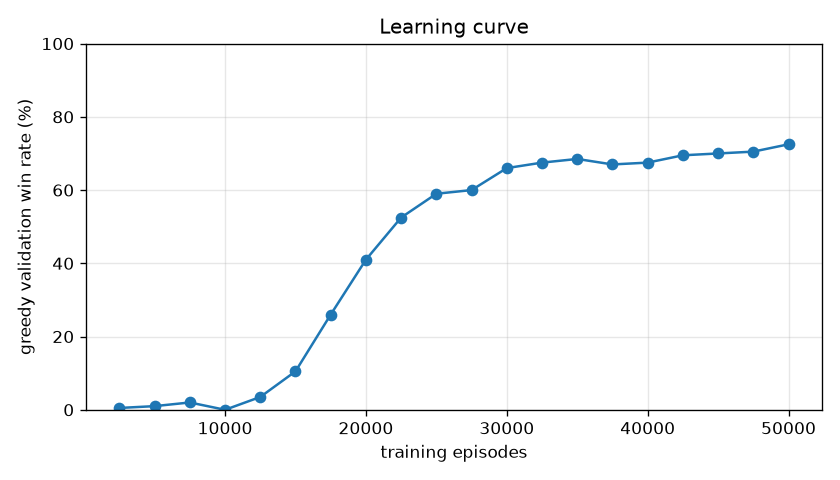

In [30]:

recorded = json.loads((WORKSPACE / "reports/results/eval-test.json").read_text())
rows = ["| Pac-Man player | Wins | Losses | Ties | Win rate |", "|---|---:|---:|---:|---:|"]
for name in ("random", "pathfinding", "learned"):
    games = [r for r in recorded["records"] if r["agent"] == name]
    counts = Counter(r["outcome"] for r in games)
    rows.append(f"| {name} | {counts['win']} | {counts['loss']} | {counts['tie']} | {counts['win'] / len(games):.1%} |")
display(Markdown("\n".join(rows)))
display(Image(filename=str(WORKSPACE / "reports/results/curve.png"), width=700))


## Run the separate 100-game random-versus-random experiment

Both characters choose uniformly among up, right, down and left. Blocked moves stay
in place and consume a turn. The four-corner goal, collision order and 100-turn limit
are unchanged. The recorded result was **2 Pac-Man wins, 89 losses and 9 ties**, with
**42.7 Pac-Man turns per game** on average. A turn includes Pac-Man's action and,
if the game continues, the ghost's action. This opponent differs from the scripted
ghost above, so the two experiments are not a matched comparison of player performance.

This cell reruns the experiment in a fresh output folder. Original recorded results
stay under `evidence/random-vs-random/`.


In [31]:

experiment_run = Path(tempfile.mkdtemp(prefix="random-vs-random-", dir=RUN_OUTPUTS))
script = experiment_run / "run.py"
shutil.copyfile(WORKSPACE / "experiments/random_vs_random.py", script)
completed = subprocess.run([sys.executable, str(script)], cwd=WORKSPACE, env=RUN_ENV,
                           capture_output=True, text=True)
if completed.returncode:
    print(completed.stdout, completed.stderr)
    completed.check_returncode()
print(completed.stdout)
fresh = json.loads((experiment_run / "results.json").read_text())
print("Average Pac-Man turns:", fresh["mean_steps"])
print("New experiment output:", experiment_run)


100 games: 2 wins, 89 losses, 9 ties (Pac-Man outcomes).
Both players choose uniformly among four directions; blocked moves stay.
Validation seeds 1000000 through 1000099; default map rules; 100-turn limit.

Average Pac-Man turns: 42.7
New experiment output: /var/folders/b7/zrvh84fd5lzdv299wwxvx5w00000gn/T/pacman-course-pe4scg9p/notebook_runs/random-vs-random-w4oejls3


## Replay a learned-player game
This is the already recorded win on seed **2,000,000**. It should end at **move 33**.
The command uses the saved policy greedily and does not train it. The final frame is
displayed below; the full plain-text replay is saved in the temporary output folder.


In [32]:

replay = run_pacman("watch", "--agent", "learned", "--seed", "2000000",
                    "--policy", str(FROZEN_POLICY), "--delay", "0", "--plain")
replay_path = RUN_OUTPUTS / "learned-replay.txt"
replay_path.write_text(replay)
print(replay.strip().split("\n\n")[-1])
print("Full replay:", replay_path)


*...*
.....
.....
?....
P.G.*
Move 33/100  Corners 4/4  Ghost sees Pac-Man: yes
Outcome: win
Full replay: /var/folders/b7/zrvh84fd5lzdv299wwxvx5w00000gn/T/pacman-course-pe4scg9p/notebook_runs/learned-replay.txt


## Optional training demonstration
Leave the switch below `False` for ordinary Run All. Setting it to `True` trains a
new, small 100-episode policy in a fresh folder. The normal training command also
runs **1,000 final validation games**, even for this short run, so it takes longer
than the 100 training episodes alone. It never changes the included frozen policy.

A full training run uses the same command without the `--set episodes=100` override.


In [33]:

RUN_TRAINING_DEMO = False
if RUN_TRAINING_DEMO:
    training_run = Path(tempfile.mkdtemp(prefix="training-demo-", dir=RUN_OUTPUTS))
    print(run_pacman("train", "--out", str(training_run), "--set", "episodes=100"))
    print("New policy and learning-curve files:", training_run)
else:
    print("Optional training is disabled. The submitted policy has not been retrained.")


Optional training is disabled. The submitted policy has not been retrained.
